# Disease enrichment for donors

In [90]:
import hashlib
import os
import tempfile
import decoupler as dc
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import matplotlib.pyplot as plt
import seaborn as sns
from urllib.request import urlopen
from scipy.stats import false_discovery_control
from utils.plotting_utils import setup_plotting_environment
setup_plotting_environment()

data_dir = "../../data/inflammation_atlas/"
baseline_path = "../../outputs/followup_screen/output_tables/4_review_change_to_median_by_donor.parquet"

BASELINE_HOURS = 24  # Choose 0 (TimePoint-0) or 24 (PBS).
baseline_conditions = {0: "TimePoint-0", 24: "PBS"}
if BASELINE_HOURS not in baseline_conditions:
    raise ValueError("BASELINE_HOURS must be 0 or 24.")
baseline_condition = baseline_conditions[BASELINE_HOURS]
baseline_tag = f"{BASELINE_HOURS}h"
baseline_label = "0 h" if BASELINE_HOURS == 0 else "24 h PBS"

SIGNATURE_GENE_SET = "pathways"  # Choose "pathways" (TNFa/NFkB targets) or "all" (all shared, filtered genes).
if SIGNATURE_GENE_SET not in {"pathways", "all"}:
    raise ValueError('SIGNATURE_GENE_SET must be "pathways" or "all".')
gene_set_tag = "tnfa_nfkb" if SIGNATURE_GENE_SET == "pathways" else "all_genes"
signature_gene_label = "TNFa/NFkB targets" if SIGNATURE_GENE_SET == "pathways" else "all shared genes"
plot_tag = f"{baseline_tag}_{gene_set_tag}"

plot_folder = "../../outputs/followup_screen/plots/disease_enrichment"
os.makedirs(plot_folder, exist_ok=True)

## 1 - Download atlas files

Downloads files from Zenodo.

In [91]:
atlas_dir = os.path.join(data_dir, "inflammation_atlas")
atlas_metadata_path = os.path.join(atlas_dir, "INFLAMMATION_ATLAS_afterQC_sampleMetadata.csv")
atlas_counts_path = os.path.join(atlas_dir, "INFLAMMATION_ATLAS_main_afterQC.h5ad")

atlas_url = "https://zenodo.org/records/14851902/files"
atlas_files = {
    atlas_metadata_path: "395e6f817fce9d5091f274d07c91359b",
    atlas_counts_path: "14fa25b5ff8d5703e13838b2f17274c5",
}

os.makedirs(atlas_dir, exist_ok=True)
for path, expected_md5 in atlas_files.items():
    if os.path.isfile(path):
        continue

    filename = os.path.basename(path)
    print(f"Downloading {filename}", flush=True)
    checksum = hashlib.md5(usedforsecurity=False)
    with tempfile.TemporaryDirectory(dir=atlas_dir) as download_dir:
        temporary_path = os.path.join(download_dir, filename)
        with urlopen(f"{atlas_url}/{filename}?download=1", timeout=120) as response:
            with open(temporary_path, "wb") as destination:
                while chunk := response.read(1024**2):
                    destination.write(chunk)
                    checksum.update(chunk)
        if checksum.hexdigest() != expected_md5:
            raise ValueError(f"Checksum mismatch for {filename}")
        os.replace(temporary_path, path)

## 2 - Load PROGENy weights

In [92]:
network_path = os.path.join(data_dir, "progeny/progeny.csv")
os.makedirs(os.path.join(data_dir, 'progeny'), exist_ok=True)
if os.path.exists(network_path):
    ranked_net = pd.read_csv(network_path)
else:
    ranked_net = dc.op.progeny(organism="human")
    ranked_net.to_csv(network_path)

PATHWAYS = ["NFkB", "TNFa"]
net = ranked_net.loc[ranked_net.source.isin(PATHWAYS), ["source", "target", "weight"]]
target_counts = net.groupby("source").target.nunique().reindex(PATHWAYS, fill_value=0)

## 3 - Check atlas cell-type annotations

The atlas supplies 17 broad Level1 labels and 66 detailed Level2 labels. The table shows their mapping. Pseudobulks use Level2, including Doublets and LowQuality_cells.

In [93]:
atlas_cells = sc.read_h5ad(atlas_counts_path, backed="r")
cell_type_definitions = (atlas_cells.obs[["Level1", "Level2"]].drop_duplicates().sort_values(["Level1", "Level2"]))
atlas_cells.file.close()

## 4 - Generate raw atlas pseudobulks

In [94]:
pseudobulk_path = os.path.join(atlas_dir, "pseudobulk_counts.h5ad")
if not os.path.isfile(pseudobulk_path):
    atlas_cells = sc.read_h5ad(atlas_counts_path)
    pseudobulk = sc.get.aggregate(atlas_cells, by=["sampleID", "Level2"], func="sum")
    pseudobulk.X = pseudobulk.layers.pop("sum")
    cell_counts = atlas_cells.obs.groupby(["sampleID", "Level2"], observed=True).size().rename("n_cells")
    pseudobulk.obs = pseudobulk.obs.join(cell_counts, on=["sampleID", "Level2"], validate="one_to_one")

    sample_metadata = pd.read_csv(atlas_metadata_path).set_index("sampleID")
    pseudobulk.obs = pseudobulk.obs.join(sample_metadata, on="sampleID")
    level1_by_level2 = cell_type_definitions.set_index("Level2")["Level1"]
    pseudobulk.obs["Level1"] = pseudobulk.obs["Level2"].map(level1_by_level2)
    pseudobulk.write_h5ad(pseudobulk_path, compression="lzf")
    print(pseudobulk)
    del atlas_cells

## 5 - Select CD14 samples for analysis

In [95]:
baseline = pd.read_parquet(baseline_path)
baseline_cd14 = baseline.xs(("CD14 Mono", baseline_condition), axis=1, level=["cell_type", "cytokine"]).T
donors = ad.AnnData(baseline_cd14.fillna(0))
donors.obs_names.name = "donor"
donors.var_names.name = "symbol"

In [96]:
pseudobulk_path = os.path.join(atlas_dir, "pseudobulk_counts.h5ad")
pseudobulk = sc.read_h5ad(pseudobulk_path, backed="r")

if "n_cells" not in pseudobulk.obs:
    atlas_cells = sc.read_h5ad(atlas_counts_path, backed="r")
    cell_counts = atlas_cells.obs.groupby(["sampleID", "Level2"], observed=True).size().rename("n_cells")
    atlas_cells.file.close()
    pseudobulk.obs = pseudobulk.obs.join(cell_counts, on=["sampleID", "Level2"], validate="one_to_one")

pseudobulk

AnnData object with n_obs × n_vars = 45245 × 22838 backed at '../../data/inflammation_atlas/inflammation_atlas/pseudobulk_counts.h5ad'
    obs: 'sampleID', 'Level2', 'Unnamed: 0', 'studyID', 'chemistry', 'technology', 'patientID', 'disease', 'timepoint_replicate', 'treatmentStatus', 'therapyResponse', 'sex', 'age', 'BMI', 'binned_age', 'diseaseStatus', 'smokingStatus', 'ethnicity', 'institute', 'diseaseGroup', 'Level1', 'n_cells'
    var: 'hgnc_id', 'symbol', 'locus_group', 'HUGO_status', 'mt', 'ribo', 'hb', 'plt', 'n_cells_by_counts', 'total_counts', 'gene_universe'

In [97]:
counts = pseudobulk.obs.groupby('Level2')['n_cells'].sum()
counts.sort_values()

/var/folders/8k/9w8xzgmj6q191ny02kp7sjqm0000gq/T/ipykernel_20825/2019405198.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = pseudobulk.obs.groupby('Level2')['n_cells'].sum()


Level2
DC_Proliferative       200
HSC_MEMP               392
T_Progenitors          868
B_Progenitors          987
DC5                   1697
                     ...  
T_CD8_Naive         213776
Doublets            240766
LowQuality_cells    241452
Mono_classical      485760
T_CD4_Naive         792955
Name: n_cells, Length: 66, dtype: int64

In [98]:
atlas = pseudobulk[(pseudobulk.obs["Level2"] == "Mono_classical") & (pseudobulk.obs["n_cells"] >= 30)].to_memory()
pseudobulk.file.close()

# define cohorts
cohort = ["studyID", "chemistry"]
atlas.obs["n_reference_donors"] = atlas.obs.groupby(cohort, observed=True)["n_cells"].transform("size")
atlas = atlas[atlas.obs["n_reference_donors"] >= 4].copy()
atlas.obs["cell_type"] = "CD14 Mono"

## 6 - Normalize and filter profiles

In [99]:
from scipy.sparse import issparse
from utils.processing_utils import normalize_df_to_rpm

# Calculate the expression filter on raw counts, including zeros in the median
MIN_MEDIAN_COUNTS = 20
raw_counts = atlas.X.toarray() if issparse(atlas.X) else atlas.X
atlas.var["median_raw_counts"] = np.median(raw_counts, axis=0)

# Match donor normalization: add 0.5 UMI, normalize to CPM, add 1, then renormalize.
normalized = normalize_df_to_rpm(pd.DataFrame(raw_counts.T), along_axis=0)
atlas.X = normalized.to_numpy().T
del raw_counts, normalized

symbols = pd.Index(atlas.var["symbol"])
shared_genes = (
    symbols.isin(donors.var_names)
    & ~symbols.duplicated(keep=False)
    & atlas.var["median_raw_counts"].ge(MIN_MEDIAN_COUNTS).to_numpy()
)
atlas = atlas[:, shared_genes].copy()
atlas.var["gene_id"] = atlas.var_names
atlas.var_names = pd.Index(atlas.var["symbol"].astype(str), name="gene_symbol")
print(f"Retained {atlas.n_vars} shared genes with median raw counts >= {MIN_MEDIAN_COUNTS}")

Retained 5364 shared genes with median raw counts >= 20


## 7 - Calculate log2 fold changes to the cohort median

In [100]:
# Match donor baseline log2FCs, including every sample in its cohort median.
for rows in atlas.obs.groupby(cohort, observed=True).indices.values():
    cohort_profiles = atlas.X[rows].copy()
    atlas.X[rows] = np.log2(cohort_profiles) - np.log2(np.median(cohort_profiles, axis=0))

atlas.obs["median_absolute_deviation_across_genes"] = np.median(np.abs(atlas.X), axis=1)
atlas.obs["median_signed_deviation_across_genes"] = np.median(atlas.X, axis=1)
metadata = atlas.obs
print(atlas)

AnnData object with n_obs × n_vars = 759 × 5364
    obs: 'sampleID', 'Level2', 'Unnamed: 0', 'studyID', 'chemistry', 'technology', 'patientID', 'disease', 'timepoint_replicate', 'treatmentStatus', 'therapyResponse', 'sex', 'age', 'BMI', 'binned_age', 'diseaseStatus', 'smokingStatus', 'ethnicity', 'institute', 'diseaseGroup', 'Level1', 'n_cells', 'n_reference_donors', 'cell_type', 'median_absolute_deviation_across_genes', 'median_signed_deviation_across_genes'
    var: 'hgnc_id', 'symbol', 'locus_group', 'HUGO_status', 'mt', 'ribo', 'hb', 'plt', 'n_cells_by_counts', 'total_counts', 'gene_universe', 'median_raw_counts', 'gene_id'


## 8 - Subset and score donor signatures

Use SIGNATURE_GENE_SET to score donor signatures using either the union of the top 500 PROGENy TNFa/NFkB targets per pathway or all shared genes passing the existing filters. Pathway diagnostics remain based on PROGENy targets.

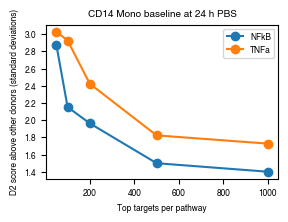

In [101]:
# 500 was chosen in advance, this is just to check that this is solid
top_gene_counts = [50, 100, 200, 500, 1000]
d2_enrichment = {}

for top_genes in top_gene_counts:
    top_net = (
        ranked_net.loc[ranked_net.source.isin(PATHWAYS)]
        .sort_values("padj")
        .groupby("source")
        .head(top_genes)
    )

    dc.mt.ulm(data=donors, net=top_net, tmin=5)
    scores = donors.obsm["score_ulm"]
    others = scores.drop(index="D2")

    d2_enrichment[top_genes] = (scores.loc["D2"] - others.mean()) / others.std(ddof=1)

enrichment = pd.DataFrame.from_dict(d2_enrichment, orient="index")
fig, ax = plt.subplots(figsize=(3,2))
enrichment.plot(marker="o", ax=ax)
ax.set_xlabel("Top targets per pathway")
ax.set_ylabel("D2 score above other donors (standard deviations)")
ax.set_title(f"CD14 Mono baseline at {baseline_label}")
fig.savefig(os.path.join(plot_folder, f"d2_pathway_target_sensitivity_{plot_tag}.svg"), dpi=300, bbox_inches="tight")
plt.show()

In [102]:
# get top genes
top_genes = 500
net_head = ranked_net.loc[ranked_net.source.isin(PATHWAYS)].sort_values("padj").groupby("source").head(top_genes)

dc.mt.ulm(data=donors, net=net_head, tmin=5)
dc.mt.ulm(data=atlas, net=net_head, tmin=5)
baseline_scores = donors.obsm["score_ulm"]
pathway_scores = atlas.obsm["score_ulm"]

In [103]:
# Select the signature genes after the existing expression and shared-gene filters.
if SIGNATURE_GENE_SET == "pathways":
    targets = pd.Index(net_head.target.unique())
else:
    targets = atlas.var_names
shared = targets.intersection(atlas.var_names).intersection(donors.var_names)

# Score donor-state enrichment using the selected genes.
donor_weights = donors[:, shared].to_df().T.rename_axis("target")
signature_net = donor_weights.reset_index().melt(id_vars="target", var_name="source", value_name="weight")

# the atlas data
signature_data = atlas[:, shared].copy()
dc.mt.ulm(data=signature_data, net=signature_net, tmin=5)
signature_scores = signature_data.obsm["score_ulm"]
atlas.obsm["score_donor_signature"] = signature_scores
atlas.obsm["padj_donor_signature"] = signature_data.obsm["padj_ulm"]
del signature_data
print(f"Scoring {len(shared)} shared genes ({signature_gene_label})")

Scoring 318 shared genes (TNFa/NFkB targets)


## 9 - Test enrichment across disease cohorts

Compare case and healthy-control mean ULM scores within each study and chemistry using 50,000 donor-label permutations for two-sided tests.  
Require at least five cases and five controls.  
Apply Benjamini–Hochberg correction separately across pathway tests, the selected donor tests, and all donor/cohort tests.  
Positive effects indicate higher case scores.

In [104]:
PERMUTATIONS = 50000
donor_of_interest = "D2"

In [105]:
def test_cohorts(scores, score_columns, alternative="two-sided"):
    if alternative not in {"two-sided", "greater"}:
        raise ValueError("alternative must be 'two-sided' or 'greater'.")
    p_column = "p_two_sided" if alternative == "two-sided" else "p_greater"
    rng = np.random.default_rng(1234)
    results = []
    for (study, chemistry), cohort in scores.groupby(["studyID", "chemistry"], observed=True):
        if cohort.patientID.duplicated().any():
            raise ValueError(f"Repeated patients in {study}, {chemistry}.")
        for disease in sorted(set(cohort.disease.dropna()) - {"healthy"}):
            pair = cohort.loc[cohort.disease.isin([disease, "healthy"])]
            case = pair.disease.eq(disease).to_numpy()
            n_case, n_control = case.sum(), (~case).sum()
            if min(n_case, n_control) < 5:
                continue
            values = pair[score_columns].to_numpy()
            case_mean = values[case].mean(axis=0)
            control_mean = values[~case].mean(axis=0)
            effect = case_mean - control_mean
            shuffled = rng.permuted(np.broadcast_to(case, (PERMUTATIONS, len(case))), axis=1)
            case_sum = shuffled.astype(float) @ values
            null = case_sum / n_case - (values.sum(axis=0) - case_sum) / n_control
            if alternative == "two-sided":
                extreme = np.abs(null) >= np.abs(effect) - 1e-12
            else:
                extreme = null >= effect - 1e-12
            p_values = (1 + extreme.sum(axis=0)) / (PERMUTATIONS + 1)
            for i, pathway in enumerate(score_columns):
                results.append((
                    study, chemistry, disease, pathway, n_case, n_control,
                    case_mean[i], control_mean[i], effect[i], p_values[i],
                ))

    tests = pd.DataFrame(results, columns=[
        "study", "chemistry", "disease", "pathway", "n_cases", "n_controls",
        "mean_case_ulm", "mean_control_ulm", "delta_mean_ulm", p_column,
    ])
    tests["q_bh"] = false_discovery_control(tests[p_column])
    return tests

# pathway enrichment
pathway_data = metadata.join(pathway_scores[PATHWAYS], validate="one_to_one")
pathway_tests = test_cohorts(pathway_data, PATHWAYS).sort_values("p_two_sided")

all_donor_data = metadata.join(signature_scores, validate="one_to_one")
all_donor_tests = test_cohorts(all_donor_data, signature_scores.columns.tolist()).rename(columns={"pathway": "signature"})

## 10 - Disease-versus-control enrichment

Rows are disease comparisons against healthy controls within the same study and chemistry.  
Diseases with multiple studies retain separate rows.

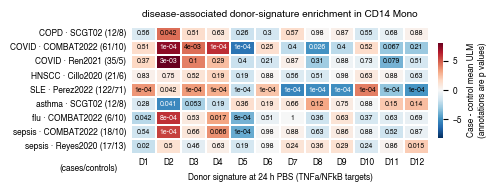

In [106]:
# Use the existing matched case-control tests and their BH correction across all signatures.
signature_order = sorted(signature_scores.columns, key=lambda name: int(name.removeprefix("D")))
row_keys = ["disease", "study", "chemistry"]
effects = all_donor_tests.pivot(index=row_keys, columns="signature", values="delta_mean_ulm").reindex(columns=signature_order).sort_index()
q_values = all_donor_tests.pivot(index=row_keys, columns="signature", values="q_bh").reindex(index=effects.index, columns=signature_order)
cohort_sizes = all_donor_tests.groupby(row_keys, observed=True)[["n_cases", "n_controls"]].first()
labels = [
    f"{disease} · {study} ({cohort_sizes.loc[key, 'n_cases']}/{cohort_sizes.loc[key, 'n_controls']})"
    for key in effects.index
    for disease, study, chemistry in [key]
]

# show chemistry where relevant (should not show up in practice)
repeated = effects.index.droplevel("chemistry").duplicated(keep=False)
labels = [f"{label} · {key[2]}" if duplicate else label for label, key, duplicate in zip(labels, effects.index, repeated)]
color_limit = max(float(np.nanmax(np.abs(effects.to_numpy()))), 0.1)

fig, ax = plt.subplots(figsize=(5.0, 2))
sns.heatmap(effects, cmap="RdBu_r", center=0, vmin=-color_limit, vmax=color_limit, linewidths=0.35, linecolor="white",
fmt="", annot_kws={"fontsize": 6, "color": "black"}, ax=ax,
cbar_kws={"label": "Case - control mean ULM\n(annotations are p values)", "shrink": 0.75, "pad": 0.025})

mesh = ax.collections[0]
for i in range(effects.shape[0]):
    for j in range(effects.shape[1]):
        effect = effects.iloc[i, j]
        p = q_values.iloc[i, j]
        if pd.isna(effect) or pd.isna(p):
            continue

        r, g, b, _ = mesh.cmap(mesh.norm(effect))
        brightness = 0.299 * r + 0.587 * g + 0.114 * b
        text_color = "white" if brightness < 0.5 else "black"

        label = f"{p:.0e}" if p < 0.01 else f"{p:.2g}"
        ax.text(j + 0.5, i + 0.5, label,ha="center", va="center",fontsize=5, color=text_color)

ax.set_yticklabels(labels, rotation=0)
ax.set_xticklabels(signature_order, rotation=0)
ax.tick_params(axis="both", length=0)
ax.set_title("disease-associated donor-signature enrichment in CD14 Mono", pad=7)
ax.set_xlabel(f"Donor signature at {baseline_label} ({signature_gene_label})")
ax.set_ylabel("")
fig.text(0.175, 0.15,"(cases/controls)", ha="center", fontsize=6)
fig.tight_layout(rect=[0, 0.05, 1, 1])

fig.savefig(os.path.join(plot_folder, f"donor_enrichment_by_disease_{plot_tag}.svg"),dpi=300, bbox_inches="tight")
plt.show()

## 11 - Is D2's disease effect stronger than every other donor's?

This is exploratory and almost unnecessarily strict - the above plot is more relevant.

For each atlas sample, calculate D2's signature score minus each other donor's signature score separately.  
Within each study and chemistry, compare each paired contrast between cases and healthy controls using 50,000 label permutations and the same minimum group sizes as Part 9.  
Each effect is D2's case-control difference minus the comparator donor's case-control difference.

These are one-sided tests of a larger disease effect for D2. To support the claim that D2 is stronger than **every** other donor, all pairwise effects must be positive and all pairwise p-values must be below 0.05. The combined intersection-union p-value, `p_stronger_than_all`, is the **maximum** pairwise one-sided p-value. No correction across the comparator donors is required for this all-donors conjunction; the displayed p-values are unadjusted across disease cohorts. The summary table also includes BH q-values across the combined cohort tests.

The heatmap shows pairwise effect differences (red: larger for D2; blue: smaller). Cell labels are raw one-sided p-values. The right column shows the combined p-value; an asterisk marks support for a larger D2 effect than every other donor at p < 0.05 within that cohort. This compares disease-associated changes, rather than absolute scores or absolute effect magnitudes, and does not by itself establish that D2's own disease effect is positive.

Method: [intersection-union permutation testing](https://pmc.ncbi.nlm.nih.gov/articles/PMC4783210/).


In [107]:
other_donors = sorted(
    signature_scores.columns.drop(donor_of_interest),
    key=lambda name: int(name.removeprefix("D")),
)
if not other_donors:
    raise ValueError("At least one other donor signature is required.")

# Keep the donor comparisons paired within each atlas sample.
pairwise_contrasts = signature_scores[other_donors].rsub(
    signature_scores[donor_of_interest], axis=0
)
pairwise_data = metadata.join(pairwise_contrasts, validate="one_to_one")
pairwise_tests = test_cohorts(
    pairwise_data, other_donors, alternative="greater"
).rename(columns={"pathway": "comparator"})

# The all-donors claim requires every component comparison to pass.
comparison_keys = ["disease", "study", "chemistry"]
all_donor_comparison = pairwise_tests.groupby(comparison_keys, observed=True).agg(
    n_cases=("n_cases", "first"),
    n_controls=("n_controls", "first"),
    n_comparators=("comparator", "nunique"),
    smallest_effect_difference=("delta_mean_ulm", "min"),
    p_stronger_than_all=("p_greater", "max"),
).sort_index()
if not all_donor_comparison["n_comparators"].eq(len(other_donors)).all():
    raise ValueError("Each cohort must include every comparator donor.")
all_donor_comparison["stronger_than_all_p05"] = (
    all_donor_comparison["smallest_effect_difference"].gt(0)
    & all_donor_comparison["p_stronger_than_all"].lt(0.05)
)
all_donor_comparison["q_bh_all_cohorts"] = false_discovery_control(
    all_donor_comparison["p_stronger_than_all"]
)

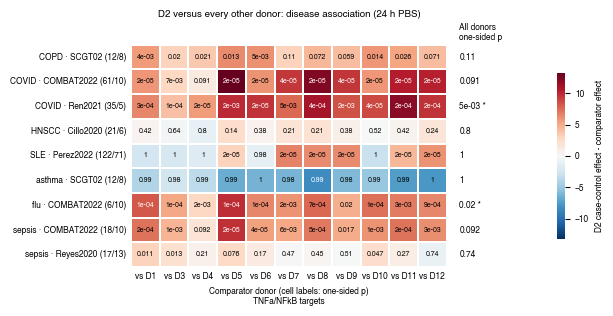

In [108]:
if pairwise_tests.empty:
    raise ValueError("No disease cohorts meet the minimum case/control counts.")

pairwise_effects = pairwise_tests.pivot(
    index=comparison_keys, columns="comparator", values="delta_mean_ulm"
).reindex(index=all_donor_comparison.index, columns=other_donors)
pairwise_p = pairwise_tests.pivot(
    index=comparison_keys, columns="comparator", values="p_greater"
).reindex(index=pairwise_effects.index, columns=other_donors)

comparison_labels = []
repeated_cohorts = pairwise_effects.index.droplevel("chemistry").duplicated(keep=False)
for i, key in enumerate(pairwise_effects.index):
    disease, study, chemistry = key
    row = all_donor_comparison.loc[key]
    label = f"{disease} · {study} ({int(row['n_cases'])}/{int(row['n_controls'])})"
    if repeated_cohorts[i]:
        label += f" · {chemistry}"
    comparison_labels.append(label)

limit = max(float(np.max(np.abs(pairwise_effects.to_numpy()))), 0.1)
fig, ax = plt.subplots(figsize=(6.4, max(2.8, 0.26 * len(pairwise_effects) + 0.8)))
sns.heatmap(
    pairwise_effects, cmap="RdBu_r", center=0, vmin=-limit, vmax=limit,
    linewidths=0.35, linecolor="white", ax=ax,
    cbar_kws={"label": "D2 case-control effect - comparator effect", "shrink": 0.75, "pad": 0.22},
)
mesh = ax.collections[0]
for i in range(pairwise_effects.shape[0]):
    for j in range(pairwise_effects.shape[1]):
        effect = pairwise_effects.iloc[i, j]
        p_value = pairwise_p.iloc[i, j]
        r, g, b, _ = mesh.cmap(mesh.norm(effect))
        text_color = "white" if 0.299 * r + 0.587 * g + 0.114 * b < 0.5 else "black"
        label = f"{p_value:.0e}" if p_value < 0.01 else f"{p_value:.2g}"
        ax.text(j + 0.5, i + 0.5, label, ha="center", va="center", fontsize=5, color=text_color)

ax.text(1.04, 1.02, "All donors\none-sided p", transform=ax.transAxes, fontsize=6)
for i, key in enumerate(pairwise_effects.index):
    row = all_donor_comparison.loc[key]
    p_value = row["p_stronger_than_all"]
    label = f"{p_value:.0e}" if p_value < 0.01 else f"{p_value:.2g}"
    if row["stronger_than_all_p05"]:
        label += " *"
    ax.text(
        1.04, i + 0.5, label, transform=ax.get_yaxis_transform(), va="center", fontsize=6,
        fontweight="bold" if row["stronger_than_all_p05"] else "normal",
    )
ax.set_yticklabels(comparison_labels, rotation=0)
ax.set_xticklabels([f"vs {donor}" for donor in other_donors], rotation=0)
ax.tick_params(axis="both", length=0)
ax.set_title(f"{donor_of_interest} versus every other donor: disease association ({baseline_label})", fontsize=7, pad=20)
ax.set_xlabel(f"Comparator donor (cell labels: one-sided p)\n{signature_gene_label}")
ax.set_ylabel("")
fig.tight_layout()
comparison_plot_path = os.path.join(plot_folder, f"{donor_of_interest.lower()}_vs_each_donor_by_disease_{plot_tag}.svg")
fig.savefig(comparison_plot_path, dpi=300, bbox_inches="tight")
plt.show()